# Ghép ảnh UAV bằng đặc trưng cổ điển: Baseline SIFT và ORB (Classical Aerial Mosaicking Baseline)

### 1. Mục đích của notebook này là gì?
Notebook này thực hiện bài toán cơ bản nhất trong xử lý ảnh UAV: **Ghép các khung hình chụp từ drone thành một bức ảnh bản đồ lớn (Aerial Mosaic)** bằng hai thuật toán thị giác máy tính truyền thống là **SIFT** và **ORB**.

### 2. Quy trình ghép ảnh hoạt động như thế nào?
Để ghép các ảnh liên tiếp với nhau, máy tính thực hiện 5 bước:
1. **Đọc dữ liệu (DataLoader):** Đọc danh sách ảnh chụp từ drone (`rgb/`) và thông số camera (`config.cfg`, `trajectory.txt`).
2. **Tìm và nối điểm giống nhau (Feature Extraction & Matching):**
   - **SIFT:** Tìm các góc, vân chi tiết với độ chính xác cao nhưng tốn thời gian tính toán hơn.
   - **ORB:** Tìm điểm đặc trưng nhị phân, chạy cực nhanh nhưng dễ bị ảnh hưởng khi ảnh xoay nhiều.
3. **Lọc điểm đúng và tìm góc biến đổi (Homography & RANSAC):**
   - Nhiều cặp điểm bị nối nhầm, thuật toán RANSAC giúp loại bỏ các điểm sai (outliers), chỉ giữ lại điểm đúng (inliers).
   - Từ các điểm đúng, máy tính tính ra ma trận biến đổi phối cảnh 3x3 ($H$) để uốn cong ảnh sau khớp vào ảnh trước.
4. **Trải khung ảnh toàn cục (Canvas Bounding Box & Stitching):**
   - Tính toán kích thước khung ảnh tổng thể để chứa vừa toàn bộ các tấm ảnh sau khi ghép.
   - Chiếu từng ảnh lên khung tranh và trộn màu (blending) để tạo thành bản đồ hoàn chỉnh.
5. **So sánh kết quả SIFT vs ORB:**
   - Chạy cả hai thuật toán trên cùng 20 khung hình đầu tiên.
   - So sánh thời gian chạy (giây), số lượng điểm đúng (inliers) và độ sai lệch (RMSE pixel).


In [13]:
# ==============================================================================
# CẤU HÌNH NHANH (QUICK CONFIG)
# Đổi "pilot" thành "full" để chạy toàn bộ dataset; giữ "pilot" để thử nghiệm nhanh.
# ==============================================================================
EXECUTION_MODE = "full"  # "pilot" hoặc "full"

import os
os.environ["UAV_EXECUTION_MODE"] = EXECUTION_MODE

import os
import sys
import time
import json
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Cloud environment guard (RULES.md §8: Experiments must run on Google Colab or Kaggle hosted runtimes only)
is_colab = bool(os.environ.get("COLAB_RELEASE_TAG")) and Path("/content").is_dir()
is_kaggle = bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE")) and Path("/kaggle").is_dir()
if not (is_colab or is_kaggle):
    raise RuntimeError(
        "Execution is restricted to hosted Google Colab or Kaggle runtimes (RULES.md §8). "
        "Local execution is prohibited."
    )

# 2. Automatically mount Google Drive if running on Colab for persistent storage
if is_colab:
    if not os.path.ismount("/content/drive"):
        from google.colab import drive
        drive.mount("/content/drive")
    if not os.path.ismount("/content/drive") or not Path("/content/drive/MyDrive").is_dir():
        raise RuntimeError("Google Drive mount failed; persistent storage unavailable.")

from datetime import datetime, timezone

print(f"Runtime:        {'Google Colab' if is_colab else 'Kaggle'}")
print(f"OpenCV Version: {cv2.__version__}")
print(f"NumPy Version:  {np.__version__}")
def resolve_paths():
    """Một root dữ liệu rõ ràng; output Colab bắt buộc nằm trên Drive đã mount."""
    default_project = "/content/drive/MyDrive/mosaicking_from_uav_video_research" if is_colab else "/kaggle/working"
    project_dir = Path(os.environ.get("UAV_PROJECT_ROOT", default_project)).expanduser().resolve()
    if not project_dir.is_dir():
        raise FileNotFoundError(f"Project directory missing: {project_dir}")
    data_dir = next((project_dir / name for name in ("dataset", "data")
                     if (project_dir / name).is_dir()), None)
    if data_dir is None:
        raise FileNotFoundError(f"Expected dataset/ or data/ inside {project_dir}")
    if is_kaggle and not os.environ.get("UAV_OUTPUT_ROOT"):
        raise ValueError("Set UAV_OUTPUT_ROOT and save Kaggle version/output for persistent handoff.")
    default_output = "/content/drive/MyDrive/mosaicking_from_uav_video_research/outputs"
    output_root = Path(os.environ.get("UAV_OUTPUT_ROOT", default_output)).expanduser().resolve()
    if is_colab and not output_root.is_relative_to(Path("/content/drive").resolve()):
        raise ValueError(f"Colab output must be on mounted Google Drive: {output_root}")
    return project_dir, data_dir, output_root

REPO_ROOT, DATA_DIR, OUTPUT_ROOT = resolve_paths()
ROOT = REPO_ROOT

def _is_safe_path(base_dir: Path, target_path: Path) -> bool:
    try:
        target_path.resolve().relative_to(base_dir.resolve())
        return True
    except ValueError:
        return False

def resolve_sequence_root(path: Path) -> Path:
    """Trả về thư mục thực sự chứa thư mục rgb, hỗ trợ cả layout lồng nhau."""
    if (path / "rgb").is_dir() and any((path / "rgb").glob("*.jpg")):
        return path
    nested = path / path.name
    if (nested / "rgb").is_dir() and any((nested / "rgb").glob("*.jpg")):
        return nested
    for p in path.rglob("rgb"):
        if p.is_dir() and any(p.glob("*.jpg")):
            return p.parent
    return path

def ensure_sequence(data_dir: Path, seq_name: str) -> Path:
    """Đảm bảo thư mục sequence có ảnh; tự động giải nén an toàn nếu chỉ có archive, không giải nén lại nếu đã có."""
    target = data_dir / seq_name
    if target.is_dir():
        resolved = resolve_sequence_root(target)
        if (resolved / "rgb").is_dir() and any((resolved / "rgb").glob("*.jpg")):
            return resolved

    import tarfile, zipfile
    for ext in (".tar.gz", ".tgz", ".zip"):
        archive = data_dir / f"{seq_name}{ext}"
        if archive.is_file():
            print(f"Giải nén an toàn {archive.name}...")
            target.mkdir(parents=True, exist_ok=True)
            target_res = target.resolve()
            if ext == ".zip":
                with zipfile.ZipFile(archive, "r") as z:
                    for member in z.infolist():
                        dest = (target / member.filename).resolve()
                        if not _is_safe_path(target_res, dest):
                            raise RuntimeError(f"Unsafe zip entry path: {member.filename}")
                    z.extractall(target)
            else:
                with tarfile.open(archive, "r:*") as t:
                    if not hasattr(tarfile, "data_filter"):
                        raise RuntimeError("Safe tar extraction requires Python with tarfile.data_filter.")
                    t.extractall(target, filter="data")
            break

    resolved = resolve_sequence_root(target)
    if not ((resolved / "rgb").is_dir() and any((resolved / "rgb").glob("*.jpg"))):
        raise FileNotFoundError(f"Sequence {seq_name} not found or missing rgb/*.jpg under {target}")
    return resolved

# Chế độ chạy: pilot (20 frames) hoặc full (toàn bộ frames tìm được)
EXECUTION_MODE = os.environ.get("UAV_EXECUTION_MODE", EXECUTION_MODE).lower()
if EXECUTION_MODE not in ("pilot", "full"):
    raise ValueError("UAV_EXECUTION_MODE must be pilot or full")

# Chọn sequence thử nghiệm (mặc định phantom3-village-kfs)
SEQUENCE_NAME = os.environ.get("UAV_SEQUENCE", "phantom3-village-kfs")
SEQUENCE_PATH = ensure_sequence(DATA_DIR, SEQUENCE_NAME)

# Unique UTC run directory: OUTPUT_ROOT / "classical_mosaicking_baseline" / <stamp>
RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = OUTPUT_ROOT / "classical_mosaicking_baseline" / RUN_STAMP
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print(f"Mode:          {EXECUTION_MODE}")
print(f"Sequence Path: {SEQUENCE_PATH.resolve()}")
print(f"Output Path:   {OUTPUT_DIR.resolve()}")

Runtime:        Google Colab
OpenCV Version: 4.14.0
NumPy Version:  2.1.3
Mode:          full
Sequence Path: /content/drive/MyDrive/mosaicking_from_uav_video_research/dataset/phantom3-village-kfs
Output Path:   /content/drive/MyDrive/mosaicking_from_uav_video_research/outputs/classical_mosaicking_baseline/20261101T153341_784110Z


In [14]:
def load_sequence(seq_path: Path):
    """Đọc danh sách ảnh keyframe và metadata (xử lý cả thư mục lồng nhau)."""
    actual_dir = seq_path
    if (seq_path / seq_path.name).is_dir() and (seq_path / seq_path.name / "rgb").is_dir():
        actual_dir = seq_path / seq_path.name

    rgb_dir = actual_dir / "rgb"
    if not rgb_dir.exists():
        raise FileNotFoundError(f"Không tìm thấy thư mục rgb trong {actual_dir}")

    # Sắp xếp ảnh theo timestamp
    img_files = sorted(
        list(rgb_dir.glob("*.jpg")) + list(rgb_dir.glob("*.png")),
        key=lambda p: float(p.stem) if p.stem.replace(".", "", 1).isdigit() else p.name
    )

    # Đọc trajectory ground truth
    traj_file = actual_dir / "trajectory.txt"
    trajectories = {}
    if traj_file.exists():
        with open(traj_file, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 8:
                    trajectories[float(parts[0])] = [float(x) for x in parts[1:]]

    # Đọc config camera
    cfg_file = actual_dir / "config.cfg"
    camera_cfg = {}
    if cfg_file.exists():
        with open(cfg_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    k, v = line.split("=", 1)
                    camera_cfg[k.strip()] = v.strip()

    return img_files, trajectories, camera_cfg

img_files, trajectories, camera_cfg = load_sequence(SEQUENCE_PATH)
print(f"Tìm thấy: {len(img_files)} frames | {len(trajectories)} pose ground truth | {len(camera_cfg)} config keys")
if img_files:
    sample = cv2.imread(str(img_files[0]))
    print(f"Frame size: {sample.shape[1]}x{sample.shape[0]} px")


Tìm thấy: 406 frames | 406 pose ground truth | 5 config keys
Frame size: 1920x1080 px


### 2. Trích xuất đặc trưng và Đối sánh (SIFT vs ORB)
Ở bước này, chúng ta lấy 2 bức ảnh đầu tiên (frame 0 và frame 1) để xem trực quan:
- SIFT và ORB tìm được những điểm nào trên mái nhà, con đường, ngọn cây.
- Các đường thẳng nối các điểm giống nhau giữa 2 bức ảnh.


SIFT:  856 matches (1239.5 ms)
ORB :  731 matches (99.2 ms)


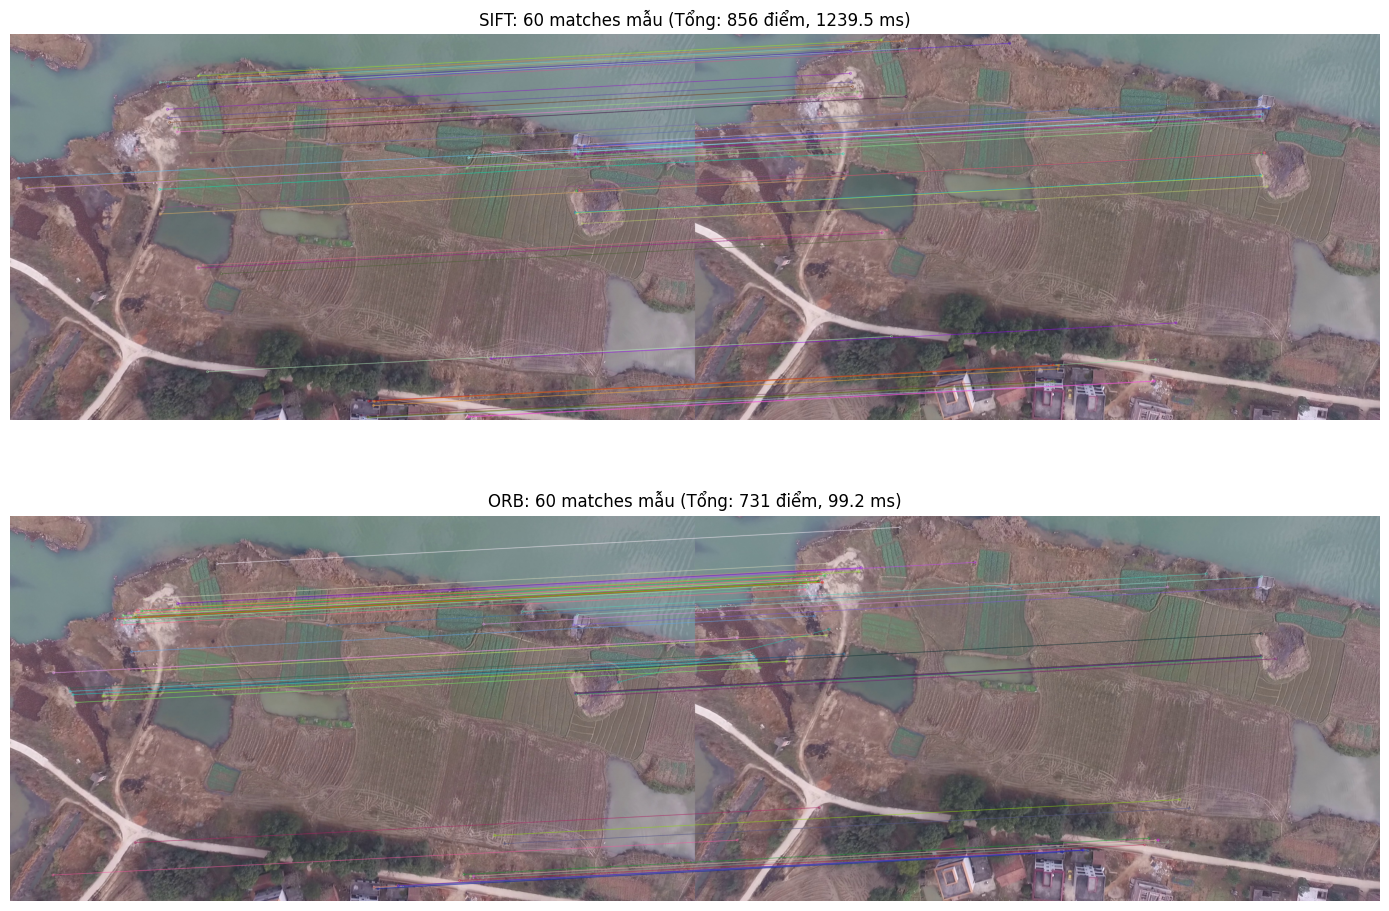

In [15]:
def extract_and_match(img1, img2, method="SIFT", max_features=2000, ratio_thresh=0.75):
    """Trích xuất keypoints và match giữa 2 ảnh bằng SIFT hoặc ORB."""
    g1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY) if len(img1.shape) == 3 else img1
    g2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY) if len(img2.shape) == 3 else img2

    t0 = time.perf_counter()
    if method.upper() == "SIFT":
        detector = cv2.SIFT_create(nfeatures=max_features)
        matcher = cv2.BFMatcher(cv2.NORM_L2)
    elif method.upper() == "ORB":
        detector = cv2.ORB_create(nfeatures=max_features)
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    else:
        raise ValueError(f"Unknown method: {method}")

    # Narrowly handle featureless/blank frames
    try:
        kp1, des1 = detector.detectAndCompute(g1, None)
        kp2, des2 = detector.detectAndCompute(g2, None)
    except cv2.error:
        return [], (), (), time.perf_counter() - t0

    if kp1 is None or kp2 is None or des1 is None or des2 is None or len(des1) < 4 or len(des2) < 4:
        return [], kp1 or (), kp2 or (), time.perf_counter() - t0

    matches = matcher.knnMatch(des1, des2, k=2)
    good = [m[0] for m in matches if len(m) == 2 and m[0].distance < ratio_thresh * m[1].distance]
    dur = time.perf_counter() - t0
    return good, kp1, kp2, dur

# Đối chiếu trực quan cả 2 thuật toán trên 2 frame đầu
if len(img_files) >= 2:
    im0 = cv2.imread(str(img_files[0]))
    im1 = cv2.imread(str(img_files[1]))

    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    for idx, m_name in enumerate(["SIFT", "ORB"]):
        m_matches, kp_a, kp_b, m_dur = extract_and_match(im0, im1, method=m_name)
        print(f"{m_name:4s}: {len(m_matches):4d} matches ({m_dur*1000:.1f} ms)")
        vis = cv2.drawMatches(im0, kp_a, im1, kp_b, m_matches[:60], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        axes[idx].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        axes[idx].set_title(f"{m_name}: 60 matches mẫu (Tổng: {len(m_matches)} điểm, {m_dur*1000:.1f} ms)")
        axes[idx].axis("off")
    plt.tight_layout()
    plt.show()


### 3. Ước lượng Homography (H) và Lọc nhiễu bằng RANSAC
- **Homography ($H$):** Là ma trận toán học 3x3 giúp dịch chuyển, xoay và uốn góc khung hình hiện tại sao cho đè khít lên khung hình trước.
- **RANSAC:** Khi tìm điểm giống nhau, luôn có những cặp điểm bị nối sai (ví dụ ngọn cây này nối nhầm sang ngọn cây khác). RANSAC là cơ chế lọc thông minh, loại bỏ các điểm sai và chỉ giữ lại những điểm nối thực sự chuẩn xác (gọi là inliers).
- **RMSE (Root Mean Square Error):** Sai số hình học tính bằng pixel giữa các điểm ghép. RMSE càng nhỏ chứng tỏ phép ghép càng khít.


In [16]:
def check_no_projective_pole(H: np.ndarray, h: int, w: int) -> bool:
    """Verifies that the denominator w(x, y) = H[2,0]*x + H[2,1]*y + H[2,2]
    does not cross zero anywhere inside the image rectangle [0, w] x [0, h].
    Since w(x, y) is affine, it is non-zero and has consistent sign over the rectangle
    iff all four corners have strictly positive or strictly negative denominators."""
    if H is None or not np.isfinite(H).all() or np.linalg.matrix_rank(H) < 3:
        return False
    corners = np.array([
        [0.0, 0.0, 1.0],
        [float(w), 0.0, 1.0],
        [float(w), float(h), 1.0],
        [0.0, float(h), 1.0],
    ], dtype=np.float64)
    denoms = corners @ H[2, :]
    if np.any(np.abs(denoms) < 1e-7):
        return False
    return bool(np.all(denoms > 0) or np.all(denoms < 0))

def estimate_homography(kp_prev, kp_curr, matches, shape_curr=None, ransac_thresh=3.0):
    """Ước lượng H từ frame curr sang frame prev bằng RANSAC."""
    if len(matches) < 4:
        return None, np.array([]), 0, 0.0, float("inf")

    pts_prev = np.float32([kp_prev[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts_curr = np.float32([kp_curr[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(pts_curr, pts_prev, cv2.RANSAC, ransac_thresh)
    if H is None or not np.isfinite(H).all() or np.linalg.matrix_rank(H) < 3:
        return None, np.array([]), 0, 0.0, float("inf")

    # Reject projective pole crossing the image
    h_c = shape_curr[0] if shape_curr is not None else (float(np.max(pts_curr[:, :, 1])) if len(pts_curr) else 640)
    w_c = shape_curr[1] if shape_curr is not None else (float(np.max(pts_curr[:, :, 0])) if len(pts_curr) else 640)
    if not check_no_projective_pole(H, h_c, w_c):
        return None, np.array([]), 0, 0.0, float("inf")

    inliers = mask.ravel().astype(bool)
    inlier_count = int(np.sum(inliers))
    inlier_ratio = inlier_count / len(matches) if len(matches) > 0 else 0.0

    if inlier_count >= 4:
        p_curr_in = pts_curr[inliers]
        p_prev_in = pts_prev[inliers]
        p_proj = cv2.perspectiveTransform(p_curr_in, H)
        rmse = float(np.sqrt(np.mean(np.linalg.norm(p_prev_in - p_proj, axis=2)**2)))
    else:
        return None, np.array([]), 0, 0.0, float("inf")

    return H, mask, inlier_count, inlier_ratio, rmse


### 4. Tạo khung tranh toàn cảnh (Canvas) và Dán ảnh (Stitching)
- Khi máy bay bay về phía trước, mỗi bức ảnh sẽ dịch đi một đoạn. Hàm `compute_canvas` tính trước diện tích của cả vùng đất cần bao phủ để khung tranh không bị cắt mất góc.
- **Cách trộn ảnh (Blend):** Các bức ảnh được dán tuần tự lên khung tranh. Ở vùng hai ảnh chồng lấn lên nhau, thuật toán trộn màu 50/50 để làm mờ đường nối giữa hai ảnh.


In [17]:
def compute_canvas(shapes, homographies):
    """Tính kích thước canvas toàn cục và ma trận tịnh tiến T."""
    all_pts = []
    for (h, w), H in zip(shapes, homographies):
        if not check_no_projective_pole(H, h, w):
            raise ValueError("Homography has a projective pole crossing the image canvas")
        corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float32).reshape(-1, 1, 2)
        warped = cv2.perspectiveTransform(corners, H)
        if not np.isfinite(warped).all():
            raise ValueError("Canvas corners are not finite")
        all_pts.append(warped.reshape(-1, 2))
    all_pts = np.vstack(all_pts)
    min_x, min_y = np.floor(all_pts.min(axis=0)).astype(int)
    max_x, max_y = np.ceil(all_pts.max(axis=0)).astype(int)
    w_canvas = max(1, max_x - min_x)
    h_canvas = max(1, max_y - min_y)
    T = np.array([[1.0, 0.0, -min_x], [0.0, 1.0, -min_y], [0.0, 0.0, 1.0]], dtype=np.float64)
    return w_canvas, h_canvas, T

def run_mosaic_pipeline(image_files, method="SIFT", num_frames=None, max_features=2000):
    """Thực thi ghép ảnh tuần tự, bộ nhớ giới hạn O(1) ảnh, ghi nhận log và ma trận homography."""
    n = len(image_files) if num_frames is None else min(len(image_files), num_frames)
    if n < 1:
        raise ValueError("Cần ít nhất 1 ảnh để tạo mosaic")

    sample0 = cv2.imread(str(image_files[0]))
    if sample0 is None:
        raise FileNotFoundError(f"Không thể đọc ảnh: {image_files[0]}")
    shapes = [sample0.shape[:2]]

    H_accum = [np.eye(3, dtype=np.float64)]
    pair_metrics = []
    print(f"Ghép {n} frames ({method})...")

    prev_img = sample0
    for i in range(1, n):
        curr_img = cv2.imread(str(image_files[i]))
        if curr_img is None:
            raise FileNotFoundError(f"Không thể đọc ảnh: {image_files[i]}")
        shapes.append(curr_img.shape[:2])

        t0 = time.perf_counter()
        good, kp_prev, kp_curr, _ = extract_and_match(prev_img, curr_img, method=method, max_features=max_features)
        H_rel, _, inliers, inlier_ratio, rmse = estimate_homography(kp_prev, kp_curr, good, shape_curr=curr_img.shape[:2])
        dur = time.perf_counter() - t0

        valid_accum = False
        if H_rel is not None:
            H_cand = H_accum[-1] @ H_rel
            if check_no_projective_pole(H_cand, curr_img.shape[0], curr_img.shape[1]):
                valid_accum = True
                H_global = H_cand

        if not valid_accum:
            print(f"  [Cảnh báo] Frame {i:02d}: RANSAC/hình học thất bại! Dừng chuỗi ghép tại đây.")
            pair_metrics.append({
                "frame": i,
                "status": "failed",
                "timestamp": Path(image_files[i]).stem,
                "method": method,
                "matches": len(good),
                "inliers": inliers if H_rel is not None else 0,
                "inlier_ratio": round(inlier_ratio, 4) if H_rel is not None else 0.0,
                "rmse": None,
                "latency_ms": round(dur * 1000, 2)
            })
            del curr_img
            break

        H_accum.append(H_global)
        pair_metrics.append({
            "frame": i,
            "status": "success",
            "timestamp": Path(image_files[i]).stem,
            "method": method,
            "matches": len(good),
            "inliers": inliers,
            "inlier_ratio": round(inlier_ratio, 4),
            "rmse": round(rmse, 4),
            "latency_ms": round(dur * 1000, 2)
        })
        if i % 5 == 0 or i == n - 1:
            print(f"  Frame {i:02d}/{n-1}: inliers={inliers:4d} ({inlier_ratio*100:5.1f}%), RMSE={rmse:4.2f}px, {dur*1000:5.1f}ms")
        prev_img = curr_img

    del prev_img

    num_stitched = len(H_accum)
    shapes_stitched = shapes[:num_stitched]

    w_canv, h_canv, T = compute_canvas(shapes_stitched, H_accum)
    max_dim = 5000
    scale = min(1.0, max_dim / max(w_canv, h_canv))
    out_w, out_h = max(1, int(w_canv * scale)), max(1, int(h_canv * scale))
    S = np.diag([scale, scale, 1.0])
    print(f"  Canvas {method}: {out_w}x{out_h} px (scale: {scale:.3f}, ghép thành công: {num_stitched}/{n} frames)")

    mosaic = np.zeros((out_h, out_w, 3), dtype=np.uint8)
    weights = np.zeros((out_h, out_w), dtype=np.float32)
    H_to_mosaic = []

    for i in range(num_stitched):
        frame_img = cv2.imread(str(image_files[i]))
        if frame_img is None:
            raise FileNotFoundError(f"Không thể đọc ảnh: {image_files[i]}")
        H_f = S @ T @ H_accum[i]
        H_to_mosaic.append(H_f.tolist())
        warped = cv2.warpPerspective(frame_img, H_f, (out_w, out_h))
        ones = np.ones(shapes_stitched[i], dtype=np.float32)
        mask = cv2.warpPerspective(ones, H_f, (out_w, out_h)) > 0.5

        overlap = weights > 0
        new_px = mask & (~overlap)
        blend_px = mask & overlap
        mosaic[new_px] = warped[new_px]
        if np.any(blend_px):
            mosaic[blend_px] = (0.5 * mosaic[blend_px].astype(np.float32) + 0.5 * warped[blend_px].astype(np.float32)).astype(np.uint8)
        weights[mask] += 1.0
        del frame_img, warped, ones, mask

    return mosaic, H_to_mosaic, pair_metrics, num_stitched


### 5. Chạy thực nghiệm SIFT & ORB và Xuất kết quả
Ở bước này, pipeline sẽ lần lượt chạy 20 khung hình cho SIFT và 20 khung hình cho ORB:
- Xuất ra 2 bức ảnh bản đồ ghép hoàn chỉnh (`mosaic_sift.png` và `mosaic_orb.png`).
- Xuất bảng so sánh chi tiết: Tổng thời gian chạy, số điểm đúng trung bình và sai số RMSE.

*Lưu ý cho sinh viên:* Chỉ số RMSE ở đây chỉ đo độ khớp nội bộ của các điểm trong cặp ảnh, chưa phản ánh được việc bản đồ có bị cong vẹo tích lũy về sau hay không (hiện tượng này sẽ được đo ở thực nghiệm đo trôi (drift)).


=== BẮT ĐẦU THỰC NGHIỆM TRÊN 406 FRAMES (Mode: full) ===

Ghép 406 frames (SIFT)...
  Frame 05/405: inliers=1194 ( 99.2%), RMSE=1.02px, 1211.4ms
  Frame 10/405: inliers=1120 ( 98.7%), RMSE=1.01px, 1307.8ms
  Frame 15/405: inliers=1054 ( 98.0%), RMSE=1.01px, 1226.9ms
  Frame 20/405: inliers=1072 ( 98.3%), RMSE=0.98px, 1224.7ms
  Frame 25/405: inliers=1086 ( 98.3%), RMSE=1.00px, 1233.5ms
  Frame 30/405: inliers= 901 ( 92.2%), RMSE=0.80px, 1511.8ms
  Frame 35/405: inliers= 733 ( 88.8%), RMSE=0.94px, 1221.3ms
  Frame 40/405: inliers= 679 ( 87.3%), RMSE=0.95px, 1228.8ms
  Frame 45/405: inliers= 918 ( 98.5%), RMSE=0.72px, 1184.9ms
  Frame 50/405: inliers= 839 ( 94.3%), RMSE=1.19px, 1258.2ms
  Frame 55/405: inliers= 899 ( 97.3%), RMSE=0.98px, 1216.6ms
  Frame 60/405: inliers= 924 ( 94.3%), RMSE=0.92px, 1197.3ms
  Frame 65/405: inliers= 994 ( 98.9%), RMSE=0.73px, 1223.9ms
  Frame 70/405: inliers= 855 ( 93.6%), RMSE=1.00px, 1247.5ms
  Frame 75/405: inliers= 851 ( 90.7%), RMSE=1.32px, 1273.3ms
 

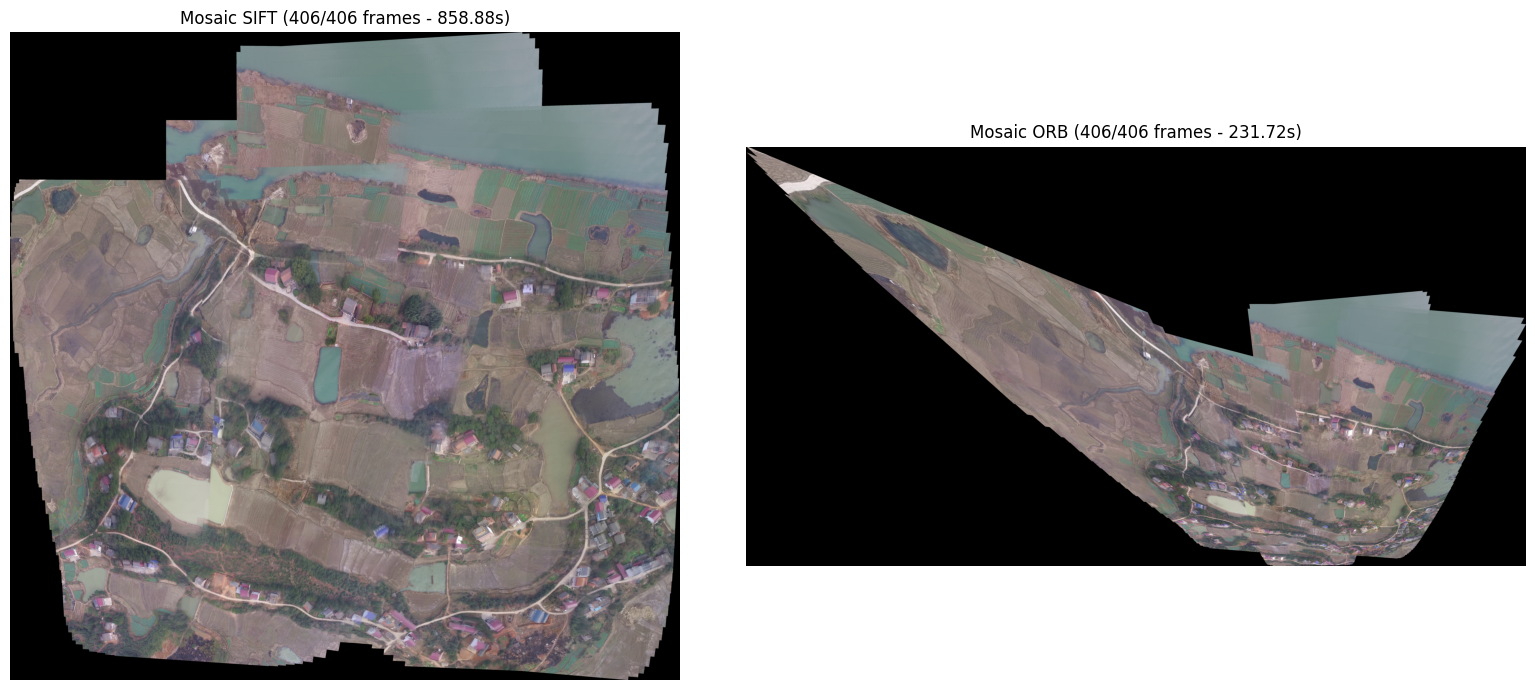

In [18]:
if (OUTPUT_DIR / "completed.json").exists():
    raise RuntimeError(f"Run directory {OUTPUT_DIR} is already marked completed. Re-run setup to allocate a fresh run directory.")

import hashlib
NUM_TEST_FRAMES = 20 if EXECUTION_MODE == "pilot" else len(img_files)
METHODS = ["SIFT", "ORB"]
selected_files = img_files[:NUM_TEST_FRAMES]

# Record ordered input frames with sha256 hashes
input_manifest = []
for p in selected_files:
    input_manifest.append({
        "name": p.name,
        "path": str(p.relative_to(ROOT)) if _is_safe_path(ROOT, p) else str(p),
        "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
        "size_bytes": p.stat().st_size
    })

OPERATIVE_CONFIG = {
    "max_features": 2000,
    "ransac_thresh": 3.0,
    "ratio_thresh": 0.75,
    "num_frames_requested": len(selected_files),
    "mode": EXECUTION_MODE
}

experiment_results = {}
created_artifacts = []

print(f"=== BẮT ĐẦU THỰC NGHIỆM TRÊN {len(selected_files)} FRAMES (Mode: {EXECUTION_MODE}) ===\n")
for method in METHODS:
    cv2.setRNGSeed(0)
    t_start = time.perf_counter()
    mosaic_img, H_mosaics, metrics, stitched_count = run_mosaic_pipeline(
        selected_files, method=method, num_frames=len(selected_files)
    )
    total_sec = time.perf_counter() - t_start

    # Lưu ảnh kết quả
    img_out = OUTPUT_DIR / f"mosaic_{method.lower()}_{len(selected_files)}frames.png"
    if not cv2.imwrite(str(img_out), mosaic_img):
        raise OSError(f"Không lưu được ảnh: {img_out}")

    # Lưu metrics log (chứa cả ma trận H_to_mosaic ánh xạ đúng vào ảnh mosaic)
    log_out = OUTPUT_DIR / f"metrics_{method.lower()}_{len(selected_files)}frames.json"
    with open(log_out, "w", encoding="utf-8") as f:
        json.dump({
            "sequence": SEQUENCE_NAME,
            "method": method,
            "backend": "cpu",
            "mode": EXECUTION_MODE,
            "num_frames_requested": len(selected_files),
            "frames_stitched": stitched_count,
            "pipeline_total_seconds": round(total_sec, 2),
            "config": OPERATIVE_CONFIG,
            "H_to_mosaic": H_mosaics,
            "frames": metrics
        }, f, indent=2, allow_nan=False)

    created_artifacts.extend([str(img_out.name), str(log_out.name)])
    experiment_results[method] = {
        "mosaic": mosaic_img,
        "total_sec": total_sec,
        "metrics": metrics,
        "frames_stitched": stitched_count,
        "img_file": img_out,
        "log_file": log_out
    }
    print(f"  Checkpointed: {img_out.name}")
    print(f"  Checkpointed: {log_out.name}\n")

# Bảng tổng hợp so sánh trực tiếp
header = f"{'THUẬT TOÁN':<12} | {'TỔNG THỜI GIAN':<16} | {'GHÉP ĐƯỢC':<14} | {'INLIERS TB':<12} | {'INLIER RATIO':<14} | {'RMSE TB':<10}"
print("=" * len(header))
print(header)
print("-" * len(header))
for method in METHODS:
    res = experiment_results[method]
    valid = [m for m in res["metrics"] if m.get("status") == "success" and m.get("rmse") is not None]
    avg_inliers = float(np.mean([m["inliers"] for m in valid])) if valid else 0.0
    avg_ratio = float(np.mean([m["inlier_ratio"] for m in valid]) * 100) if valid else 0.0
    avg_rmse = float(np.mean([m["rmse"] for m in valid])) if valid else None
    sec_str = f"{res['total_sec']:.2f} s"
    ratio_str = f"{avg_ratio:.1f} %"
    rmse_str = f"{avg_rmse:.2f} px" if avg_rmse is not None else "N/A"
    stitched_str = f"{res['frames_stitched']}/{len(selected_files)} frames"
    print(f"{method:<12} | {sec_str:<16} | {stitched_str:<14} | {avg_inliers:<12.1f} | {ratio_str:<14} | {rmse_str:<10}")
print("=" * len(header))

# Cloud Self-checks: geometry, projective pole rejection, and featureless handling
# 1. Projective pole crossing canvas must be rejected
H_pole = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.01, 0.0, -1.0]], dtype=np.float64)
assert not check_no_projective_pole(H_pole, 480, 640), "Self-check failed: projective pole was not rejected!"
assert check_no_projective_pole(np.eye(3), 480, 640), "Self-check failed: identity matrix was rejected!"

# 2. Insufficient matches (<4) must fail cleanly without throwing
bad_H, _, _, _, _ = estimate_homography([], [], [], shape_curr=(480, 640))
assert bad_H is None, "Self-check failed: empty matches did not return None H!"

# 3. Blank image feature extraction must handle zero features cleanly
blank = np.zeros((100, 100, 3), dtype=np.uint8)
blank_matches, _, _, _ = extract_and_match(blank, blank, method="SIFT")
assert len(blank_matches) == 0, "Self-check failed: blank image produced non-empty matches!"
print("PASS: Cloud self-checks passed successfully.")

# Write completed.json LAST after all runs and checks succeed
completed_manifest = {
    "completed_at": datetime.now(timezone.utc).isoformat(),
    "status": "success",
    "experiment": "classical_mosaicking_baseline",
    "sequence": SEQUENCE_NAME,
    "mode": EXECUTION_MODE,
    "methods": METHODS,
    "num_frames_requested": len(selected_files),
    "config": OPERATIVE_CONFIG,
    "inputs": input_manifest,
    "artifacts": created_artifacts,
    "provenance": {
        "opencv": cv2.__version__,
        "numpy": np.__version__,
        "platform": sys.platform
    }
}
with open(OUTPUT_DIR / "completed.json", "w", encoding="utf-8") as f:
    json.dump(completed_manifest, f, indent=2, allow_nan=False)
print(f"Completed run marker written: {OUTPUT_DIR / 'completed.json'}")

# Hiển thị trực quan cả 2 bức ảnh ghép cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for idx, method in enumerate(METHODS):
    axes[idx].imshow(cv2.cvtColor(experiment_results[method]["mosaic"], cv2.COLOR_BGR2RGB))
    axes[idx].set_title(f"Mosaic {method} ({experiment_results[method]['frames_stitched']}/{len(selected_files)} frames - {experiment_results[method]['total_sec']:.2f}s)")
    axes[idx].axis("off")
plt.tight_layout()
plt.show()